# Thresholding

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

### Simple thresholding

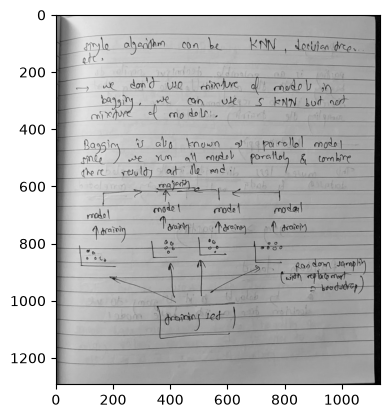

In [2]:
img = cv2.imread('./data/handwritten.jpeg', 0)
plt.imshow(img, 'grey')

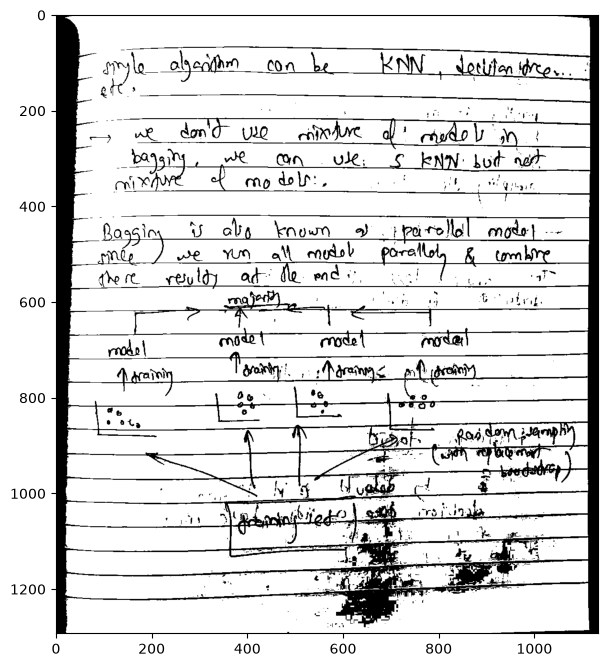

In [3]:
retval, binary_msk = cv2.threshold(src=img, thresh=150, maxval=255, type=cv2.THRESH_BINARY)
'''
255 if pixel > 150, else 0
'''
plt.figure(figsize=(7,12))
plt.imshow(binary_msk, 'grey')

### Adaptive thresholding

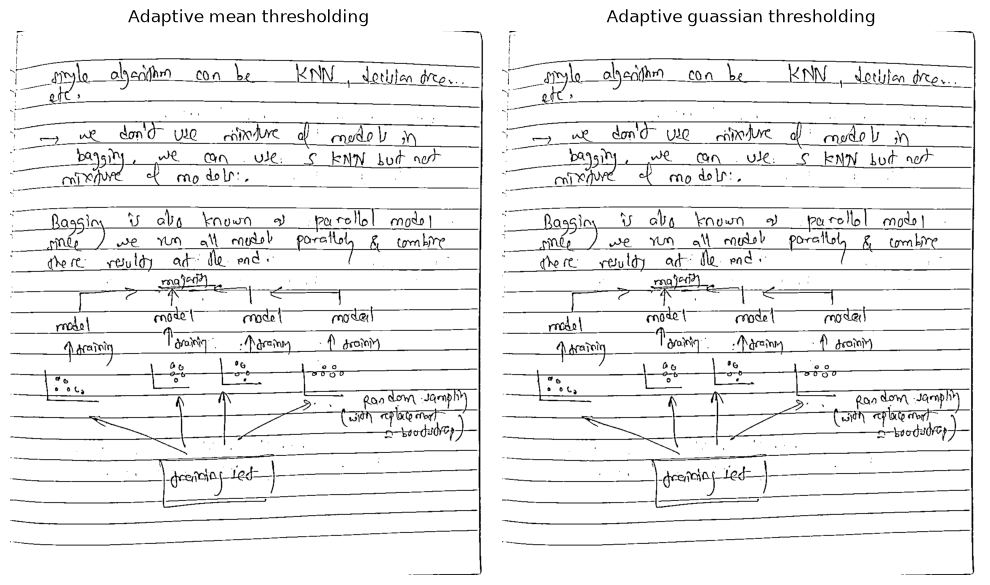

In [4]:
adapt_mean = cv2.adaptiveThreshold(src=img, # Input 8-bit single-channel (grayscale) image
                                   maxValue=255, # Output value assigned to pixels classified as foreground
                                   adaptiveMethod=cv2.ADAPTIVE_THRESH_MEAN_C, # Calculate the local threshold using the neighborhood mean
                                   thresholdType=cv2.THRESH_BINARY, # Pixels above the local threshold become 255; others become 0
                                   blockSize=11,  # Size of the local neighborhood (11 × 11 pixels); must be an odd integer greater than 1
                                   C=25) # Constant subtracted from the calculated local threshold

adapt_gaus = cv2.adaptiveThreshold(src=img, # Input 8-bit single-channel (grayscale) image
                                   maxValue=255, # Output value assigned to pixels classified as foreground
                                   adaptiveMethod=cv2.ADAPTIVE_THRESH_MEAN_C, # Calculate the local threshold using a Gaussian-weighted sum of neighborhood pixels
                                   thresholdType=cv2.THRESH_BINARY, # Pixels above the local threshold become 255; others become 0
                                   blockSize=11,  # Size of the local neighborhood (11 × 11 pixels); must be an odd integer greater than 1
                                   C=25) # Constant subtracted from the calculated local threshold


plt.figure(figsize=(10, 24))

plt.subplot(1,2,1)
plt.imshow(adapt_mean, cmap='grey')
plt.title("Adaptive mean thresholding")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(adapt_gaus, cmap='grey')
plt.title("Adaptive guassian thresholding")
plt.axis('off')

plt.tight_layout()
plt.show()

# kmeans clustering

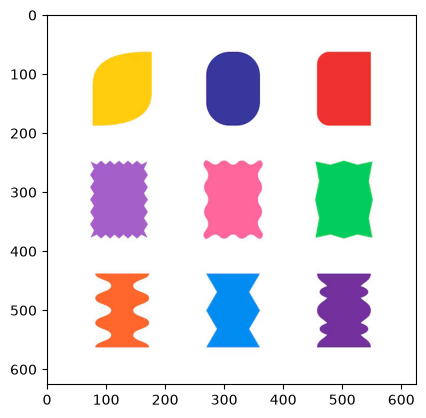

In [5]:
img = cv2.imread('./data/shapes.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img)

In [6]:
print(img.shape) # 3-dimension data

(626, 626, 3)


In [7]:
# Prepare data for kmeans clustering algorithm
pixel_val = img.reshape((-1,3)).astype(np.float32) # suitable data type for OpenCV's K-Means implementation
print(pixel_val.shape) # 2-dimension data

(391876, 3)


In [8]:
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
'''
NOTE: Define the termination criteria for the K-Means algorithm. As per documentation:

--> criteria = (type, maxCount, epsilon)

cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER
--> Stop when either the required accuracy is reached or the maximum number of iterations is reached

100
--> Maximum number of iterations allowed

0.2
--> Epsilon: Stop if the cluster centers change by less than this threshold

'''

k = 3 # number of clusters

_, labels, centers = cv2.kmeans(data=pixel_val, # pixel color values, typically shaped (number_of_pixels, 3) and converted to float32
                                K=k, # number of clusters to create
                                bestLabels=None, # no initial cluster assignments are provided; OpenCV initializes them based on the selected flags
                                criteria=criteria, # termination criteria controlling when the algorithm stops
                                attempts=10, # run the algorithm 10 times with different initial cluster centers and retain the best result
                                flags=cv2.KMEANS_RANDOM_CENTERS) # initialize cluster centers randomly

In [9]:
print(labels.shape)
print(centers) # 3 clusters with XYZ values

(391876, 1)
[[ 70.9147   110.96521  167.68669 ]
 [255.2777   255.2192   255.20657 ]
 [249.43346  114.88152   69.147255]]


In [10]:
np.unique(labels.flatten(), return_counts=True)

(array([0, 1, 2], dtype=int32), array([ 51279, 299214,  41383]))

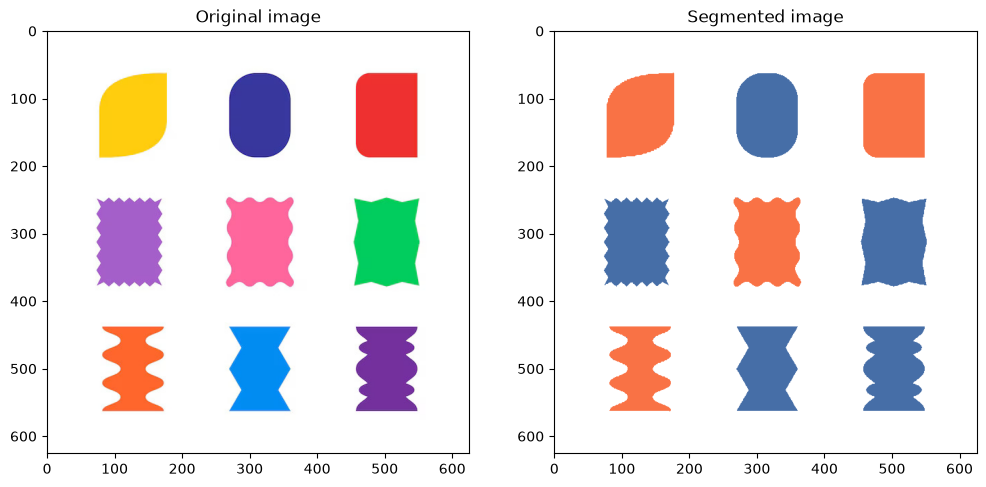

In [11]:
# Reconstruct the image
centers = np.uint8(centers) # convert to 8-bit unsigned integer
segmented_img = centers[labels.flatten()].reshape(img.shape)

# Label indexing
# 0 --> [70,110, 167]
# 1 --> [255, 255, 255]
# 2 --> [249 114  69]

plt.figure(figsize=(12,7))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title("Original image")

plt.subplot(1,2,2)
plt.imshow(segmented_img)
plt.title("Segmented image")

plt.show()

In the image, only can see 2 categories. The remaining one is the whole image itself.

# watershed algorithm

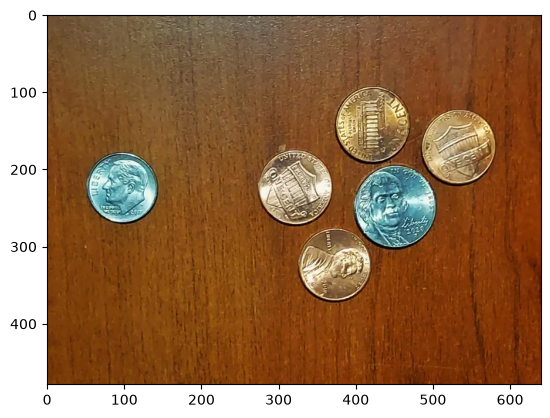

In [2]:
img = cv2.imread('./data/coin2.jpg')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
original_img = img_rgb.copy()
plt.imshow(original_img)

### 1. Convert the Image to Grayscale

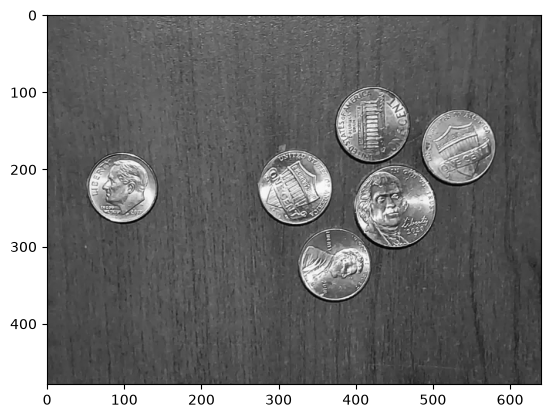

In [3]:
img_grey = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
plt.imshow(img_grey, 'gray')

**Purpose**: Simplifies the image by removing color information, making thresholding easier.

### 2. Apply Binary Thresholding

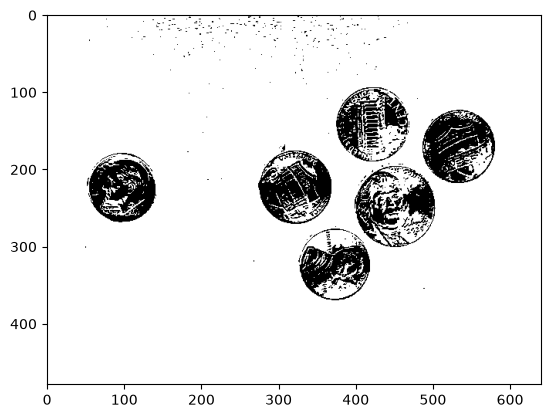

In [4]:
_, bin_thresh = cv2.threshold(src=img_grey, # input 8-bit single-channel (grayscale) image
                          thresh=130,   # pixels > 130 = 0; pixels ≤ 0 = 255
                          maxval=255,   # maximum output value assigned to pixels that meet the inverse threshold condition
                          type=cv2.THRESH_BINARY_INV) # inverse binary thresholding: pixels > 130 = 0; pixels ≤ 130 = 255

plt.imshow(bin_thresh, cmap='grey')

**Purpose**: Separates the coins from the background by converting the grayscale image into a binary image.

- Pixels with intensity ≤ 130 become white (255).  
- Pixels with intensity > 130 become black (0).  

The effectiveness depends on the brightness of the coins and background.

### 3. Apply Morphological Opening

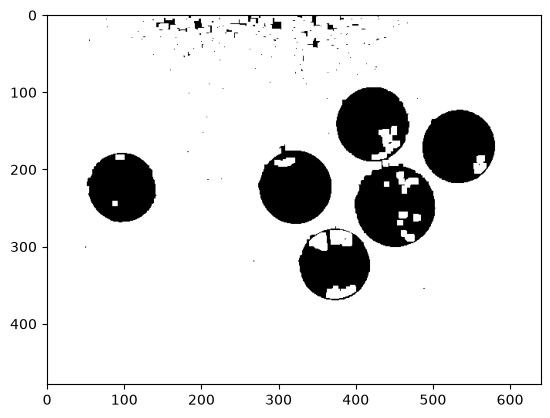

In [5]:
kernel = np.ones((3,3), np.uint8)

# Remove small white noise and tiny foreground objects from a binary image using a morphological operation called Opening
opening = cv2.morphologyEx(src=bin_thresh, 
                           op=cv2.MORPH_OPEN, # perform morphological opening: erosion followed by dilation
                           kernel=kernel, # structuring element that defines the neighborhood used for the operation
                           iterations=3) # repeat the opening operation 4 times

plt.imshow(opening, 'grey')

**Purpose**: Removes small white noise and unwanted foreground objects.

Morphological opening consists of:

1. `Erosion`: Shrinks white regions.
2. `Dilation`: Restores the remaining regions toward their original size.

### 4. Identify the Sure Background

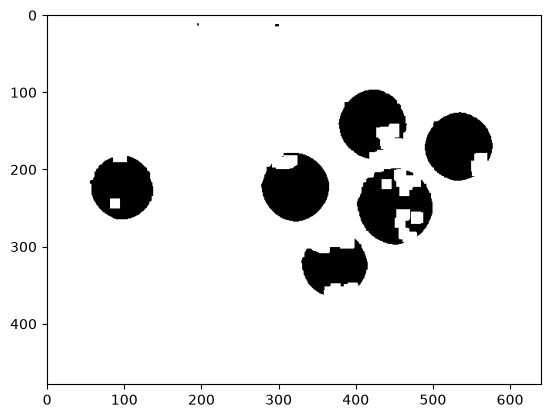

In [6]:
# Dilate the binary image to expand the foreground regions
sure_bg = cv2.dilate(src=opening,      # Input binary image after morphological opening
                     kernel=kernel,     # Structuring element that determines the dilation shape
                     iterations=3)     # Apply dilation 3 times to expand the white regions

plt.imshow(sure_bg, 'grey')

**Purpose**: Expands the foreground regions to create a larger area that is confidently associated with the foreground objects' surroundings.

In the watershed workflow, this provides an approximate region containing the coins.

### 5. Calculate the Distance Transform

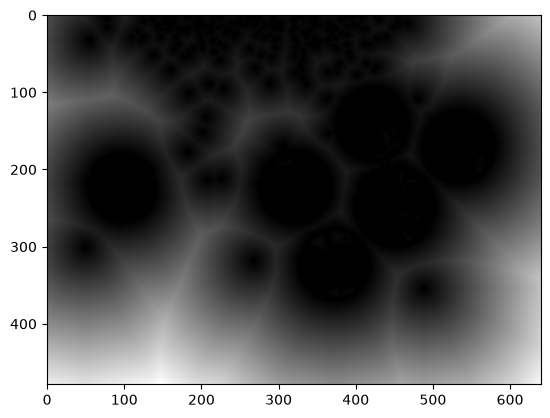

In [7]:
# Calculate the distance from each foreground pixel to the nearest background pixel
dist_transform = cv2.distanceTransform(src=opening, 
                                       distanceType=cv2.DIST_L2, # use Euclidean distance to measure the distance to the nearest zero pixel
                                       maskSize=5) # use a 5 × 5 mask to approximate the Euclidean distance
plt.imshow(dist_transform, 'grey')

**Purpose**: Calculates the distance from each foreground pixel to the nearest background pixel.

The centers of coins generally have larger distance values than their edges. This helps identify the central regions of coins, even when coins touch each other.

### 6. Identify the Sure Foreground

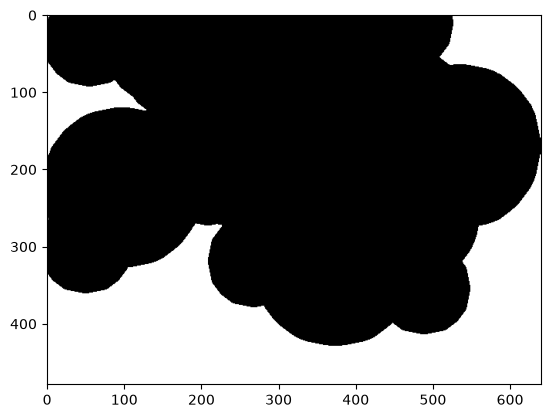

In [8]:
# Apply binary thresholding to the distance transform to identify sure foreground regions
_, sure_fg = cv2.threshold(src=dist_transform, 
                           thresh=0.3 * dist_transform.max(), # Threshold at 30% of the maximum distance value
                           maxval=255,  # assign 255 to pixels that exceed the threshold
                           type=cv2.THRESH_BINARY) # # pixels above the threshold become 255; all others become 0

sure_fg = np.uint8(sure_fg)

plt.imshow(sure_fg, cmap='grey')

**Purpose**: Identifies the central portions of coins as foreground markers.

The threshold is set to 30% of the maximum distance value. This helps create seed regions for individual coins.

### 7. Identify the Unknown Region

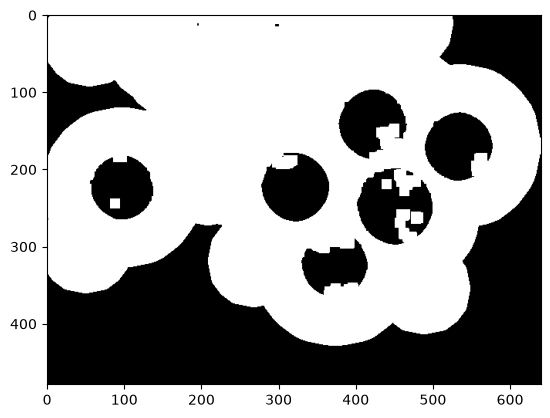

In [9]:
unknown = cv2.subtract(sure_bg, sure_fg)
plt.imshow(unknown, cmap='grey')

**Purpose**: Identifies pixels that are not classified as sure foreground but lie within the sure-background mask.

These pixels are treated as unknown regions that watershed segmentation will classify.

### 8. Generate Markers Using Connected Components

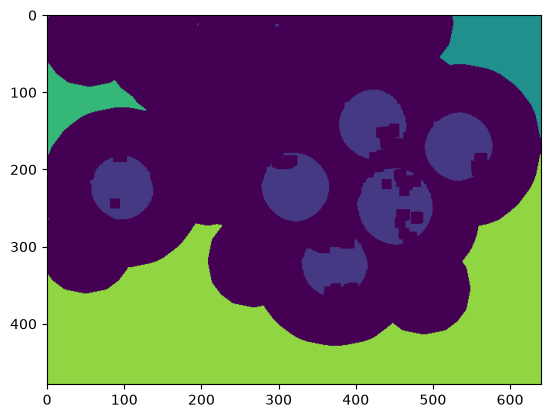

In [10]:
# Identify connected foreground components in the sure foreground image
_, markers = cv2.connectedComponents(image=sure_fg)  # Binary image containing the sure foreground regions
# The unique values of markers --> 0,1,2,3,4,5

# Add 1 to every marker label so that the background becomes 1 instead of 0
markers = markers + 1 # unique values --> 1,2,3,4,5,6

# Mark unknown regions as 0 so watershed can determine their labels
markers[unknown == 255] = 0

plt.imshow(markers)

**Purpose**: Assigns labels to the separate foreground regions.
- `connectedComponents()` identifies connected foreground regions.
- `markers + 1` shifts the labels so the background has label 1 and foreground objects have labels starting at 2.
- Unknown pixels are assigned label 0.
These markers provide starting points for watershed segmentation.

### 9. Apply Watershed Segmentation

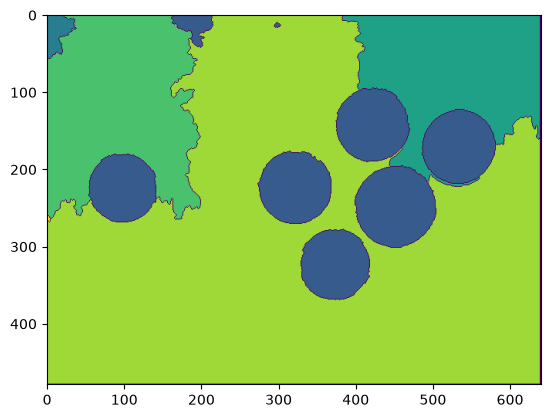

In [11]:
# Apply watershed segmentation to separate objects and identify their boundaries
old_markers = markers.copy()
watershed_seg = cv2.watershed(img, old_markers) # unique values: [-1  1  2  3  4  5  6]
# -1 --> watershed boundary between regions
# 1 --> Background marker, assuming you shifted the original labels by 1
# 2 to 6 --> Foreground regions or other labeled regions
plt.imshow(watershed_seg)

**Purpose**: Separates touching or overlapping coins by assigning pixels to different regions based on the image's boundaries.

The resulting marker image contains:
- `Positive labels`: Identified regions.
- `-1`: Watershed boundary pixels.
- `0`: Any remaining unknown pixels.
This step is particularly important when coins touch one another.

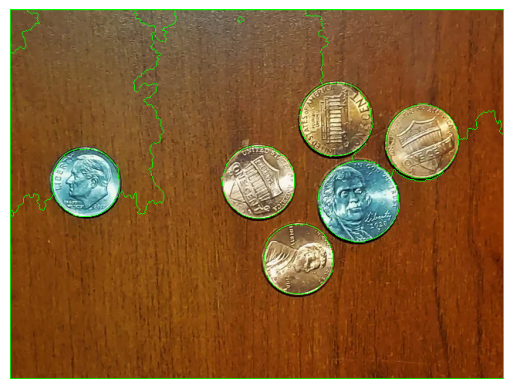

In [12]:
# Highlight watershed boundaries in red (BGR color)
image = img.copy()
image[watershed_seg == -1] = [0, 255, 0]

# Display the segmented image
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

### Remaining steps from 10 to 16

In [13]:
coin_mask = np.zeros_like(img_grey)
print(img_grey.shape, coin_mask.shape)
np.unique(coin_mask)

(479, 640) (479, 640)


array([0], dtype=uint8)

In [14]:
unique_labels = np.unique(watershed_seg)
unique_labels

array([-1,  1,  2,  3,  4,  5,  6], dtype=int32)

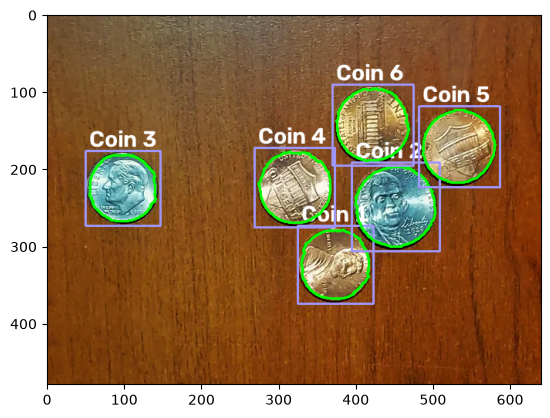

In [25]:
final_img = img_rgb.copy()
instance_number = 1 # initialize the coin counter, starting from Coin 1
font = cv2.FONT_HERSHEY_SIMPLEX # select the font used to display coin labels

for label in unique_labels:
    # Skip label 0 (unknown/unassigned regions, if present)
    # and label -1 (watershed boundaries)
    if label == 0 or label == -1:
        continue

    mask = np.uint8(watershed_seg == label) # converts the Boolean values into 8-bit integers

    # Detect the outer boundary of the current segment region
    contours, _ = cv2.findContours(image=mask, 
                                   mode=cv2.RETR_EXTERNAL, # retrieves outermost contours, ignoring inner contours 
                                   method=cv2.CHAIN_APPROX_SIMPLE) # compresses contour points by retaining essential points, 
                                                                   # such as the endpoints of straight lines.
    for contour in contours:
        # Calculates the area enclosed by the contour
        area = cv2.contourArea(contour)

        # Calculate the perimeter
        perimeter = cv2.arcLength(curve=contour, closed=True)

        # Prevents division by zero when calculating circularity
        if perimeter == 0:
            continue

        # Measures how closely the contour resembles a circle.
        circularity = 4 * np.pi * (area / (perimeter * perimeter))

        if 0.7 < circularity < 1.1 and area > 1000:
            cv2.drawContours(image=final_img, 
                             contours=[contour], # a list containing the current contour.
                             contourIdx=-1,      # draws all contours provided in the list
                             color=(0,255,0),    # green in OpenCV's BGR color format.
                             thickness=2)        # sets the outline thickness to 2 pixels.

            # Calculate the bounding rectangle
            x, y, w, h = cv2.boundingRect(contour)

            # Add a text label to the image to identify the detected coin
            cv2.putText(img=final_img,                   # Image on which the text will be drawn
                        text=f"Coin {instance_number}",  # Text to display, e.g., "Coin 1"
                        org=(x, y-10),                   # Bottom-left coordinates of the text in (x, y) format
                        fontFace=font,                   # Font style used to display the text
                        fontScale=1,                     # Font size scale factor
                        color=(255,255,255),             # Text color in BGR format (blue)
                        thickness=2)                     # Thickness of the text strokes in pixels

            coin_mask = cv2.bitwise_or(coin_mask, mask)

            # Draw a rectangle around the detected coin
            cv2.rectangle(img=final_img,        # Image on which the rectangle will be drawn
                          pt1=(x-5, y-5),          # Top-left corner, with a 5-pixel margin
                          pt2=(x+w+5, y+h+5),      # Bottom-right corner, with a 5-pixel margin
                          color=(160, 150, 250),   # Rectangle color in BGR format
                          thickness=2)             # Thickness of the rectangle border in pixels

            instance_number += 1
            

plt.imshow(final_img)

### 10. Extract the Contours of Individual Regions
**Purpose**: Extracts the external contours of each watershed region.

The operations are:
1. np.unique(markers) obtains all distinct region labels.
2. Skip labels 0 and -1, which represent unknown pixels and watershed boundaries.
3. markers == label creates a binary mask for the current region.
4. cv2.findContours() identifies the boundaries of the region.
Important: A watershed region is not automatically a coin. Some regions may represent noise, background fragments, or incorrectly segmented objects. Therefore, you need to filter the contours.

---

### 11. Calculate the Area and Perimeter
**Purpose**: Measures the contour's size and boundary length.
| Function | What it measures |
|---|---|
| `cv2.contourArea()` | Area enclosed by the contour, in square pixels |
| `cv2.arcLength(contour, True)` | Perimeter of the contour; `True` means the contour is closed |


You also check whether the perimeter is zero to prevent division by zero when calculating circularity.

---

### 12. Calculate Circularity
**Purpose**: Measures how closely a contour resembles a circle.  
The formula is:
$$\boxed{C = \frac{4\pi A}{P^2}}$$

$$A=\pi r^2,\qquad P=2\pi r$$

Where:
- C = circularity
- A = contour area
- P = contour perimeter
- $\pi$ ≈ 3.14159

Circularity generally ranges from near 0 for elongated or irregular shapes to 1 for a perfect circle.

| Shape | Approximate circularity |
|---|---:|
| Perfect circle | 1.00 |
| Nearly circular object | 0.85–0.95 |
| Square | 0.79 |
| Long, thin object | Much closer to 0 |

---

### 13. Filter the Coin Contours
**Purpose**: Selects contours that are sufficiently circular and large enough to be potential coins.

Your filtering conditions are:
- `0.7 < circularity < 1.2`: Rejects many irregularly shaped contours.
- `area > 1000`: Rejects small regions that are unlikely to be coins.
These values are empirical thresholds that depend on image resolution, coin size, and image quality. They may need adjustment for other images.

---

### 14. Draw the Detected Contour and Bounding Rectangle
Purpose: Visually highlights the detected coin.
- `cv2.drawContours()` draws the coin's contour in green.
- `cv2.boundingRect()` calculates the smallest upright rectangle enclosing the contour.
- `cv2.rectangle()` draws a slightly larger rectangle around the coin.

---

### 15. Label Each Detected Coin
**Purpose**: Assigns a sequential number to each contour that passes your filtering conditions.

For example, the detected coins are labeled Coin 1, Coin 2, Coin 3, and so on.


### 16. Combine the Detected Coin Masks

**Purpose**: Combines the masks of detected coins into a single binary mask.

This allows you to collect the detected coins in one image and use the combined mask for further processing, such as extracting the coins from the original image.

> Note: In your current code, mask represents the entire watershed region. If you want to combine only the specific contour that passes the circularity and area filters, you should create a separate mask for that contour.

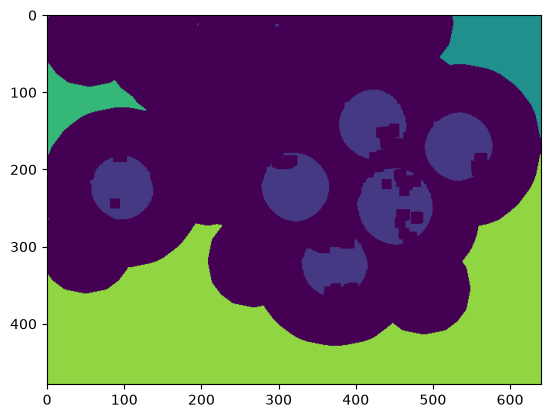

In [16]:
plt.imshow(markers)

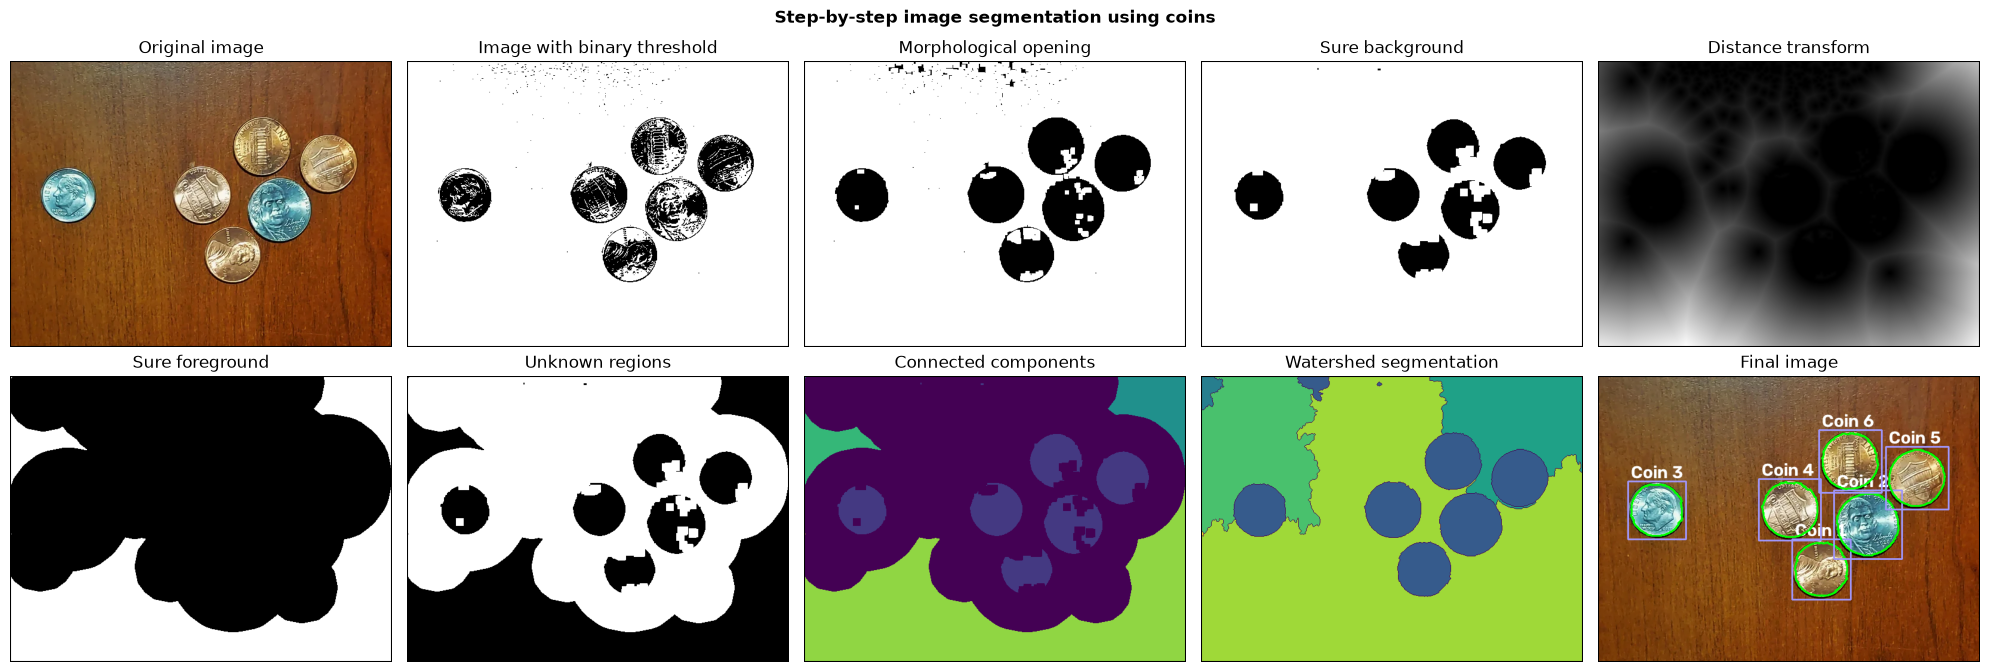

In [26]:
images = {"Original image": img_rgb,
          "Image with binary threshold": bin_thresh,
          "Morphological opening": opening,
          "Sure background": sure_bg,
          "Distance transform": dist_transform,
          "Sure foreground": sure_fg,
          "Unknown regions": unknown,
          "Connected components": markers,
          "Watershed segmentation": watershed_seg,
          "Final image": final_img}

img_type = [None,'grey','grey','grey','grey','grey','grey',None,None, None]

fig, axs = plt.subplots(2,5, figsize=(20,7))

# For loop
for ax, type, (title, image) in zip(axs.flat, img_type, images.items()):
    ax.imshow(image, type)
    ax.set_title(title)
    ax.axis('off')

    # Add a rectangular boundary around each image
    boundary = Rectangle(xy=(0, 0),               # Bottom-left corner
                         width=1,                 # Width (100% of the axes)
                         height=1,                # Height (100% of the axes)
                         transform=ax.transAxes,  # Use axes-relative coordinates (0 to 1)
                         fill=False,              # Do not fill the rectangle
                         edgecolor='black',       # Boundary line color
                         linewidth=1.5)           # Boundary line thickness
    

    ax.add_patch(boundary)

plt.suptitle("Step-by-step image segmentation using coins", weight='bold', size=12)
plt.tight_layout()
plt.savefig("./output/Image segementation.jpg")
plt.show()
